In [1]:
import torch
from diffusers import DDPMScheduler
from lurssen.models.unet import ConditionalUNet
import torch.nn.functional as F
from lurssen.encoder import RoomGenEncoder
from lurssen.dataset import get_dataloader

def train_diffusion_epoch(
    model,
    encoder,
    train_loader,
    noise_scheduler,
    optimizer,
    device
):

    model.train()
    encoder.train()

    total_loss = 0.0

    for floorplan, outershell_mask, node_features, edge_features in train_loader:

        floorplan = floorplan.to(device)
        outershell_mask = outershell_mask.to(device)

        node_features = [
            x.to(device) for x in node_features
        ]

        edge_features = [
            x.to(device) for x in edge_features
        ]
        # Add batch dimension if necessary
        if floorplan.ndim == 3:
            floorplan = floorplan.unsqueeze(0)

        if outershell_mask.ndim == 3:
            outershell_mask = outershell_mask.unsqueeze(0)

        # Generate condition
        with torch.no_grad():

            condition = encoder(
                outershell_mask,
                node_features[0],
                edge_features[0]
            )

        # Sample random noise
        noise = torch.randn_like(floorplan)

        # Sample random timesteps
        timesteps = torch.randint(
            0,
            noise_scheduler.config.num_train_timesteps,
            (floorplan.shape[0],),
            device=device
        ).long()

        # Add noise to clean images
        noisy_images = noise_scheduler.add_noise(
            floorplan,
            noise,
            timesteps
        )
        # Predict noise
        noise_pred = model(
            noisy_images,
            timesteps,
            condition
        )
        # Calculate loss
        loss = F.mse_loss(
            noise_pred,
            noise
        )
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            list(encoder.parameters()) +
            list(model.parameters()),
            max_norm=1.0
        )
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(train_loader)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ConditionalUNet(
    condition_channels=64,
    image_channels=3
).to(device)
encoder = RoomGenEncoder().to(device)
noise_scheduler = DDPMScheduler(
    num_train_timesteps=1000,
    beta_schedule="squaredcos_cap_v2",
    prediction_type="epsilon"
)
optimizer = torch.optim.AdamW(
    list(encoder.parameters()) +
    list(model.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

train_loader = get_dataloader(num_samples=1, batch_size=1, seed=41)

num_epochs = 100
for epoch in range(num_epochs):
    loss = train_diffusion_epoch(
        model=model,
        encoder=encoder,
        train_loader=train_loader,
        noise_scheduler=noise_scheduler,
        optimizer=optimizer,
        device=device
    )
    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Loss: {loss:.6f}"
    )

/home/dominik/miniconda3/envs/nlp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/dominik/miniconda3/envs/nlp/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Epoch 1/100 | Loss: 1.069069
Epoch 2/100 | Loss: 1.027046
Epoch 3/100 | Loss: 1.009054
Epoch 4/100 | Loss: 0.984499
Epoch 5/100 | Loss: 0.941739
Epoch 6/100 | Loss: 0.936632
Epoch 7/100 | Loss: 0.898649
Epoch 8/100 | Loss: 0.938079
Epoch 9/100 | Loss: 0.810170
Epoch 10/100 | Loss: 0.929114
Epoch 11/100 | Loss: 0.908074
Epoch 12/100 | Loss: 0.794925
Epoch 13/100 | Loss: 0.770236
Epoch 14/100 | Loss: 0.902355
Epoch 15/100 | Loss: 0.629023
Epoch 16/100 | Loss: 0.697086
Epoch 17/100 | Loss: 0.753864
Epoch 18/100 | Loss: 0.560022
Epoch 19/100 | Loss: 0.669511
Epoch 20/100 | Loss: 0.515177
Epoch 21/100 | Loss: 0.577608
Epoch 22/100 | Loss: 0.526467
Epoch 23/100 | Loss: 0.816113
Epoch 24/100 | Loss: 0.430521
Epoch 25/100 | Loss: 0.468858
Epoch 26/100 | Loss: 0.512808
Epoch 27/100 | Loss: 0.434675
Epoch 28/100 | Loss: 0.380928
Epoch 29/100 | Loss: 0.378532
Epoch 30/100 | Loss: 0.330560
Epoch 31/100 | Loss: 0.720159
Epoch 32/100 | Loss: 0.639543
Epoch 33/100 | Loss: 0.288534
Epoch 34/100 | Loss

In [7]:
@torch.no_grad()
def sample(
    encoder,
    model,
    noise_scheduler,
    outershell_mask,
    node_features,
    edge_features,
    device,
    image_size=256,
    channels=3
):
    encoder.eval()
    model.eval()

    # Generate condition
    condition = encoder(
        outershell_mask.to(device),
        node_features.to(device),
        edge_features.to(device)
    )

    batch_size = condition.shape[0]

    # Start from Gaussian noise
    image = torch.randn(
        batch_size,
        channels,
        image_size,
        image_size,
        device=device
    )

    noise_scheduler.set_timesteps(
        noise_scheduler.config.num_train_timesteps,
        device=device
    )

    for t in noise_scheduler.timesteps:

        noise_pred = model(
            image,
            t.expand(batch_size),
            condition
        )

        image = noise_scheduler.step(
            noise_pred,
            t,
            image
        ).prev_sample

    return image


floorplan, outershell_mask, node_features, edge_features = next(iter(train_loader))

img = sample(
    encoder,
    model,
    noise_scheduler,
    outershell_mask,
    node_features[0],
    edge_features[0],
    device,
    image_size=256,
    channels=3
)



Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


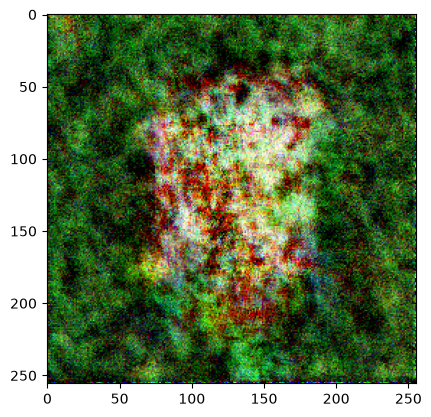

In [14]:
import matplotlib.pyplot as plt
plt.imshow(img.cpu().squeeze().permute(1,2,0))